# Training the Network

## Backpropagation

As an error-based supervised learning technique, the use of Feedforward Neural Networks is dependent on us having a means of estimating how well our model performs on individual training examples, and having a mechanism to update the parameters of the model based on the estimation of that performance. In this section we cover how this is done for the Neural Network.

For linear and logistic regression we calculated the change to be made to model parameters directly using the partial derivative of the model's error surface with respect to each individual parameter. For neural networks the approach of calculating the partial derivatives for all parameters in parallel will not work due to the layered nature of the network.

Instead of depending on these parallel weight adjustments, the backpropagation algorithm gives us a way to estimate the error derivatives for nodes found in hidden layers by taking the error derivatives in subsequent layers and redistributing that derivative amongst all nodes that lead into a given node in a way that is dependent on the strength of weights.

<!-- backporop.png -->
<img width="300" src="https://drive.google.com/uc?id=1MWvlFP_vYFtSb0vAc77BqYkKhnynXk53"/>


To illustrate consider the simple constellation of neurons above where superscript refers to layer number, subscript refers to individual units within a layer and $\delta$ denotes the error derivative for a given unit. Assuming we have computed error derivative $\delta^{2}_{1}$ successfully, we will use that error derivative along with the weights from layer 1 to layer 2 and the activation values for layer 1 to estimate an error derivative for each neuron in layer 1. In vectorized notation this is:

\begin{equation}
\delta^{l} = (\theta^{l})^{T}\; \delta^{l+1} .\times h'(z^{l})
\end{equation}

where $h'(z^{l})$ is the partial derivative of the $L^{th}$ layer's activation function and is given by:

\begin{equation}
h'(z^{l}) = a^{l} \; (1-a^{l})
\end{equation}

We can use this method to calculate error derivatives for each of the hidden layers. We do not do this for the input layer as there is by definition no error in the input layer as the activation values from the input layer are taken directly from our input vector $x$ which should not change. Note that $.\times$ is used here to denote the array multiplication operation, i.e. the element wise multiplication of two matrices where either both matrices have the same size or one matrix is a scalar. This is very different to the matrix multiplication operator.

The backpropagation algorithm involves the recursive application of $\delta$ from the output layer through each of the hidden layers.

For the output layer there is no succeeding layer on which we can base a recursive calculation of $\delta$. Instead for the output layer we calculate the error derivatives $\delta$ directly using a non-recursive definition that includes the difference between activation values and target values for the output layer. This separate calculation of $\delta$ is given below:

\begin{equation}
\delta = (a-y) .\times h'(z^{l})
\end{equation}

or given the definition of $h'(z^{l})$ established above:

\begin{equation}
\delta = (a-y) \; (a \; (1-a))
\end{equation}

The backpropagated value for $\delta$ establishes the gradient of the error associated with each hidden unit in the network, but this value in itself does not say anything about the changes which we should make to our parameters $\theta$ to improve classification. Changes to our parameter weights are calculated with a separate equation that makes use of the calculated values for $\delta$ along with activation values. Specifically the changes to be made to individual weights are given in a vectorized form below:

\begin{equation}
  \Delta^{l-1} = \delta \; a^{l-1}_{i}  
\end{equation}

where $\Delta$ is defined as the partial derivative of error with respect to individual weights.

As with linear and logistic regression we accumulate errors over a number of different training examples. We denote the total updates for node j in layer l by $\Delta_{ij}^{l}$.

## The Backpropagation Algorithm

The Backpropagation Algorithm itself involves the systematic calculation of $\delta$ and $\Delta$ across layers starting with the output layers.

Given

> A set of training data $ Data_{Training} = \{ (x^{0},y^{0}),(x^{1},y^{1}),(x^{2},y^{2})\dots (x^{m-1},y^{m-1}) \}$

> A network with weights randomly initialized between -1 and 1

For each instance i in the training data:

> Forward Propagate $x[i]$ through the network

> Backpropagate Error Derivatives back through the network

> > Calculate error derivative for final layer using $\delta = (a-y) \; (a (1-a))$ for $y[i]$

> > Calculate error derivative for hidden layers using $ \delta^{l} = \sum_{j} ( \delta^{l+1} \; \theta^{l}_{i} ) \; h'(z^{l})$

> > For each hidden layer accrue weight updates $\Delta_{ij}^{(l)} = \Delta_{ij}^{(l)} + a_{j}^{(l)}\delta_{i}^{(l+1)} $

> Update weights with accrued weight changes $\theta = \theta + \Delta$

The implementation of this algorithm is relatively straightforward, but there are some important points to keep in mind. We do not in practice calculate errors for bias units. The reason for this is that the error in a bias unit is not back-propagated to previous layers since bias units do not have weights leading into them. However the weights leading out from bias units do have calculated errors. These errors are calculated on the basis of the activation of the bias unit on the errors on nodes in the $i+1^{th}$ layer.


## Going Deep -- Deriving the Backpropagation Equations

In the notes above we simply stated the equations that are used to implement backpropagation. Based on these equations it is possible to implement backpropagation correctly, but it is useful to understand the derivation of these equations -- particularly since the derivations are straightforward. In the following we outline those derivations.

### Error
The goal of the Backpropagation Algorithm is to find an adjustment to each weight in the network to reduce total error.

We can calculate the total error for a single training example for a single output neuron of the network using the sum of squared error function:

\begin{equation*}
   E = \frac{1}{2} (y - a)^{2}
\end{equation*}

where $a$ is the actual activation values for an output unit and $y$ is the expected values of the unit for a training case. Note that our usual sum over training cases $\sum$ is missing because for notational clarity we are dealing with the result for a single training case rather than the set of training cases.

### Calculating Error Gradients for the Output Units

Our goal in training a neuron is to determine the changes we can make to individual weights leading into the neuron in order to reduce this error. To determine the best changes to make to the weights we calculate the partial derivative of the error with respect to individual input weights.

\begin{equation}
\frac{\partial E}{\partial \theta_{i}}
\end{equation}

where $i$ is the $i^{th}$ input to the neuron (including a bias input). While this notation is common, it does not take account of the layered structure of the network. The weights $\theta_{i}$ actually technically belong not to the layer which we are calculating the error derivative for, $l$, but to the proceeding layer $l-1$. Therefore we can more correctly write the above as:

\begin{equation}
\frac{\partial E}{\partial \theta^{l-1}_{i}}
\end{equation}

This figure is the gradient of the error surface for a given weight. Knowing it we can adjust our weights to try to minimize the error. However this figure is difficult to compute directly. To compute it we rely on the chain rule in order to calculate this figure in terms of a number of components:

\begin{equation}
\frac{\partial E}{\partial \theta^{l-1}_{i}} = \frac{\partial E}{\partial a}  \frac{\partial a}{\partial z}  \frac{\partial z}{\partial \theta^{l-1}_{i}}
\end{equation}

The first of these three components can be derived directly using the power rule.

\begin{align*}
                             E &= \frac{1}{2} (y - a)^{2}\\
 \frac{\partial E}{\partial a} &= 2 (\frac{1}{2}) (y-a)^{1} (-a^{0})\\
                               &= (y-a) (-1)\\
                               &= a-y
\end{align*}

The second of these $\frac{\partial a}{\partial z}$ is referred to in some sets of notes as $h'(z)$ since it is the derivative of the logistic function. This partial derivative is mathematically more tough than the component above and is dependent on the known derivative of the logistic function $a = \frac{1}{1+e^{-z}}$. This partial derivative is:

\begin{equation}
 \frac{\partial a}{\partial z} = a (1-a)
\end{equation}

The third component $\frac{\partial z}{\partial \theta^{l-1}_{i}}$ can be calculated relatively straightforwardly from the definition of $z$. (In the notation below we introduce superscripts to denote layers.)

\begin{align*}
   z^{l} &= \sum_{i=1}^{N} ( \theta^{l-1}_{i} a^{l-1}_{i} ) + b^{l-1} * 1\\
  \frac{\partial z}{\partial \theta^{l-1}_{i}} &= (\theta^{l-1}_{i})^{0} * a^{l-1}_{i}\\
                                         &= 1 * a^{l-1}_{i}\\
                                         &= a^{l-1}_{i}
\end{align*}

Combining these three factors gives us an equation for the gradient of the error with respect to an individual input weight:

\begin{equation}
\frac{\partial E}{\partial \theta^{l-1}_{i}} = (a-y) \; (a (1-a)) \; a^{l-1}_{i}
\end{equation}

This is the basic form of the **delta rule**. The delta rule defines the error with respect to individual weights but simultaneously defines the changes we need to make to the weight in order to reduce the error. If the derivative is low we are close to an error minimum and thus make a small change to the weights. If the derivative is much higher we are far away from a minimum and thus must make a much larger change to the weights.

Rather than writing $\frac{\partial E}{\partial \theta^{l-1}_{i}} $ for the derivative of the error with respect to weights we often write an upper case delta $\Delta$. Similarly by convention we often write $ \frac{\partial E}{\partial z} = \frac{\partial E}{\partial a}  \frac{\partial a}{\partial z}$, the derivative of the Error with respect to the input of a unit, simply as a lower case delta $\delta$. These notational conventions are summarized below:

\begin{align*}
  \Delta^{l-1} &= \frac{\partial E}{\partial \theta^{l-1}_{i}} \\
  \Delta^{l-1} &= \frac{\partial E}{\partial a}  \frac{\partial a}{\partial z}  \frac{\partial z}{\partial \theta^{l-1}_{i}} \\
  \Delta^{l-1} &= (a-y) \; (a (1-a)) \; a^{l-1}_{i}  \\
  \delta &= \frac{\partial E}{\partial z} \\
  \delta &= \frac{\partial E}{\partial a}  \frac{\partial a}{\partial z} \\
  \delta &= (a-y) \; (a (1-a))
\end{align*}

Therefore

\begin{equation}
  \Delta^{l-1} = \delta \; a^{l-1}_{i}  
\end{equation}

or

\begin{equation}
  \Delta = \delta^{l+1} \; a_{i}  
\end{equation}

### Calculating Error Gradients for Hidden Layer Units

Note that $\Delta$ is dependent on the activation values of the nodes connected by a given weight and on the target value for the node in the second layer. The target value for the second layer node when that second layer is the output layer is given directly to us. But when that second node is in a hidden layer we can't directly say what the target value should be for a hidden node.

For nodes in the hidden layers we get around this problem by calculating $\frac{\partial E}{\partial a}$ in a different way.  Instead we use the principle of backpropagation to take the error derivative in a node in a later layer and pass the blame back to nodes in the preceeding layer in a way that is proportional to the weights connecting the layers. This idea of propagating the error backwards is directly analogous to the propagation of activation forwards through the network. While many sets of notes describe this as the backpropagation of the error, it is important to understand that we are in fact backpropagating $\delta$, i.e., the derivative of the error with respect to logit values.

Breaking this down, the partial derivative of the total Error with respect to the activation of a neuron in the $l-1^{th}$ row is equal to the sum of partial derivative of errors on neurons in the $l^{th}$ row with respect to the activation of the neuron in the $l-1^{th}$ row, i.e.,:

\begin{equation}
    \frac{\partial E^{l-1}}{\partial a^{l-1}} = \sum_{j}  \frac{\partial E_{j}^{l}}{\partial a^{l-1}}
\end{equation}

The partial derivative of the error in a row $l$ neuron with respect to the activation of a row $l-1$ neuron can be broken down as follows:

\begin{equation}
 \frac{\partial E^{l}}{\partial a^{l-1}} =  \frac{\partial E^{l}}{\partial a^{l}} \frac{\partial a^{l}}{\partial z^{l}}  \frac{\partial z^{l}}{\partial a^{l-1}}
\end{equation}

The first two components of this equation have been seen before above. They are:

\begin{align*}                   
 \frac{\partial E^{l}}{\partial a^{l}} &= a^{l}-y^{l} \\
 \frac{\partial a^{l}}{\partial z^{l}}  &= a^{l} (1-a^{l})
\end{align*}

The third component $\frac{\partial z^{l}}{\partial a^{l-1}}$ can be calculated in an analogous way to how we calculated $\frac{\partial z}{\partial \theta^{l-1}_{i}}$ previously, i.e.,

\begin{align*}
   z^{l} &= \sum_{i=1}^{N} ( \theta^{l-1}_{i} a^{l-1}_{i} ) + b^{l-1} * 1\\
  \frac{\partial z^{l}}{\partial a^{l-1}} &= \theta^{l-1}_{i} * (a^{l-1}_{i})^{0}\\
                                      &= \theta^{l-1}_{i} * 1\\
                                      &= \theta^{l-1}_{i}
\end{align*}

Plugging these components back in to our definition of $\frac{\partial E^{l}}{\partial a^{l-1}}$ we have:

\begin{equation}
 \frac{\partial E^{l}}{\partial a^{l-1}} = (a^{l}-y^{l}) \;  a^{l} (1-a^{l}) \; \theta^{l-1}_{i}
\end{equation}

or

\begin{equation}
 \frac{\partial E^{l}}{\partial a^{l-1}} = \delta^{l} \; \theta^{l-1}_{i}
\end{equation}

since we previously established $\delta^{l} = (a^{l}-y^{l}) \;  a^{l} (1-a^{l}) $.

Plugging this into our definition of $\frac{\partial E^{l-1}}{\partial a^{l-1}}$ we have:

\begin{equation}
    \frac{\partial E^{l-1}}{\partial a^{l-1}} = \sum_{j} \delta^{l} \; \theta^{l-1}_{i}
\end{equation}

which in turn can be plugged in to our $l-1$ definition of the $\Delta$ rule equation:

\begin{equation}
\frac{\partial E^{l-1}}{\partial \theta^{l-2}_{i}} = \frac{\partial E^{l-1}}{\partial a^{l-1}}  \frac{\partial a^{l-1}}{\partial z^{l-1}}  \frac{\partial z^{l-1}}{\partial \theta^{l-2}_{i}}
\end{equation}

to give

\begin{equation}
\frac{\partial E^{l-1}}{\partial \theta^{l-2}_{i}} =  \sum_{j} ( \delta^{l} \; \theta^{l-1}_{i} )  \frac{\partial a^{l-1}}{\partial z^{l-1}}  \frac{\partial z^{l-1}}{\partial \theta^{l-2}_{i}}
\end{equation}

But
\begin{equation}
  \delta^{l-1} = \frac{\partial E^{l-1}}{\partial a^{l-1}}  \frac{\partial a^{l-1}}{\partial z^{l-1}}
\end{equation}

Therefore, we have a recursive definition of $\delta$:

\begin{equation}
  \delta^{l-1} = \sum_{j} ( \delta^{l} \; \theta^{l-1}_{i} ) \frac{\partial a^{l-1}}{\partial z^{l-1}}
\end{equation}

or

\begin{equation}
  \delta^{l-1} = \sum_{j} ( \delta^{l} \; \theta^{l-1}_{i} ) \; h'(z^{l-1})
\end{equation}

Expressing this in terms of the $l^{th}$ layer we have:

\begin{equation}
  \delta^{l} = \sum_{j} ( \delta^{l+1} \; \theta^{l}_{i} ) \; h'(z^{l})
\end{equation}

i.e., $\delta$ or $\frac{\partial E}{\partial z}$ in a given layer $l-1$ is defined in terms of the values of $\delta$ for layer $l$. This is important as it allows us to define $\delta$ and in turn $\Delta$ in hidden layers without needing to know exactly what expected value a unit should have.



## Implementing Backprop

The above set out first the principles of backprop and then the derivations that underpin it. When it comes to implementing backprop, we don't in practice need to make use of the derivations. Instead we can plough ahead with just the main functions.

Remember that we are going to start with the partial derivative of the error in the output layer, and then use that partial derivative as a component for the calculation of the partial derivative in the next to last layer, and so forth.

We need to keep track of 5 sets of variables:
- Our weights
- our logits
- our activation values
- delta with a little d
- Delta with a big D

We also need to know our inputs and outputs from the training data.

In [1]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from time import perf_counter

def standardize(x):
    col_means = np.mean(x,axis=0)
    col_std = np.std(x,axis=0)
    return (x - col_means) / col_std , col_means, col_std

def h_linear(theta,X):
    z = np.matmul(theta,X)
    return z

def h_logistic(theta,X):
    z = np.matmul(theta,X)
    return 1 / (1 + np.exp(-z))

# In this implementation we force all vectors to be true 2D arrays with 1 column rather than
# numpy 1D arrays. This makes it easier to use matirx operations.

class Backpropogation:

    def __init__(self,x,y,s):
        # set class references to X and Y
        self.X = x
        self.Y = y
        self.S = s
        # Define empty arrays for activation
        self.a     =  [None] * len(self.S)
        # Define empty array for z values (i.e., inputs)
        self.z     =  [None] * len(self.S)
        # Define empty arrays for weights
        self.theta =  [None] * len(self.S)
        # Define empty array for error derivitives for indivual units
        self.delta =  [None] * len(self.S)
        # Define empty arrays for accumulated errors on weights
        self.Delta =  [None] * len(self.S)

        # Randomly Initialize the weights for all layers
        for idx, val in enumerate(self.S):
            if idx == (len(self.S)-1): # ouput layer has no weights
                break
            self.theta[idx] = np.random.rand( self.S[idx]+1,self.S[idx+1])

    # calculate the squared error given a list of actual values and a list of target values
    def sqError(self,a,y):
        return np.sum(np.multiply(0.5,(a-y)**2))

    def forwardProp(self,x):
        # Forward propogate activation
        # For each layer from input to output
        for idx, val in enumerate(self.S):
            if idx == 0:
                # construct the activation values for the input layer from X and a bias value
                self.a[idx] = np.atleast_2d(np.hstack(([1.0],x))).T
            elif idx == (len(self.S)-1):
                # calculate z for the output layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate a for the output layer∂E/∂zⱼ * ∂zⱼ/∂wᵢ
                self.a[idx] = 1 / (1 + np.exp(-self.z[idx]))
            else:
                # calculate z for a hidden layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate a for a hidden layer
                self.a[idx] = np.vstack(([1.0],1 / (1 + np.exp(-self.z[idx]))))
        # return the actual output values for the output layer
        return self.a[len(self.S)-1]

    def predict(self,X):
        results = []
        for datum in X:
            results.append(self.forwardProp(datum))
        return np.squeeze(results)

    def backwardProp(self,y):
        # For each layer from output to input
        for idx, val in reversed(list(enumerate(self.S))):
            if idx == (len(self.S)-1):
                # calculate ∂a/∂z for the output layer
                gprimez = np.multiply(self.a[idx],(1 - self.a[idx]))
                # ∂E/∂zⱼ
                self.delta[idx] = np.multiply(self.a[idx] - y,gprimez)
            elif idx == 0:
                # we need to update the weights in the 0th layer but we don't propogate error
                # derivitive back to the input units.
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T
            else:
                # calculate the error for all other layers

                # 1. calculate the derivitive of a with respect to z
                gprimez = np.multiply(self.a[idx],(1 - self.a[idx]))

                # 2. calculate the error associatd with each node in the current layer.
                self.delta[idx] = np.multiply(np.matmul(self.theta[idx],self.delta[idx+1]),gprimez)

                # get rid of the bias unit
                self.delta[idx] = self.delta[idx][1:,:]

                # 3. update the accumulated change
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T

        return self.sqError(self.a[len(self.S)-1],y)

    def train(self,epochs):
        errors = []
        # For each training epoch
        for k in range(epochs):
            error = 0
            # Initialize Delta for this epoch
            for idx, val in enumerate(self.S):
                if idx < (len(self.S)-1): # ouput layer has no weights
                    self.Delta[idx] = np.zeros((self.S[idx]+1,self.S[idx+1]))
            # Iterate over all training examples
            for i, y in enumerate(self.Y):
                self.forwardProp(self.X[i])
                error += self.backwardProp(y)
            errors.append(error)
            # For each layer from output to input
            for idx, val in reversed(list(enumerate(self.S))):
                if idx < (len(self.S)-1):
                    # Update the weights
                    self.theta[idx] = self.theta[idx] - (1/len(self.Y)) * self.Delta[idx]
        return errors

    def test(self):
        for i, y in enumerate(self.Y):
            output = self.forwardProp(self.X[i])
            print(self.X[i])
            print(output)
            print("---")

To test our neural network implementation we will begin with the simple example of a XNOR operation. This is a classic example in Neural Network training as it is one of the more basic operations that cannot be learned without hidden units. For XNOR we have 1 output variable and 2 input variables where all variables are binary. As a reminder from the last section, this is the truth table for the XNOR operation:

x1 | x2 | x1 XNOR x2
--- | --- | :---:
0 |	0 |	1
0 |	1 |	0
1 |	0 |	0
1 | 1 | 1

We will proceed by defining the sample data and then calling on the training process.

[0 0]
[[0.04581165]]
---
[0 1]
[[0.95576153]]
---
[1 0]
[[0.49666571]]
---
[1 1]
[[0.50292756]]
---


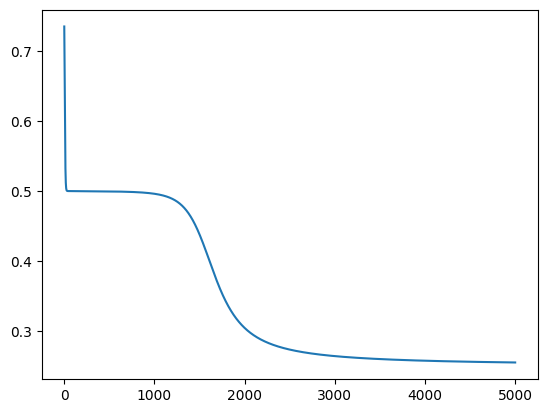

In [2]:
# Define the training data
Y = np.array([  0,1,1,0])
X1 = np.array([ 0,0,1,1])
X2 = np.array([ 0,1,0,1])
X = np.vstack((X1,X2)).T

# Define the number of (visible) units in each layer
s = [2,2,1]

# Instantiate the network with data and topology, before running training and printing results
bp = Backpropogation(X,Y,s)
errors = bp.train(5000)
bp.test()

# Visualize Error over Epochs
plt.plot(errors)
plt.show()

For a second example we will look again at the non-linear logistic regression example that we previously considered. In this case the positive examples are clustered together and negative examples form a ring around that cluster as illustrated below.

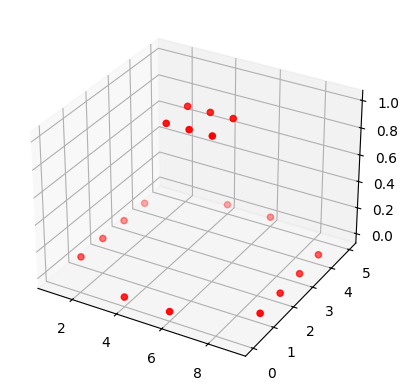

In [3]:
# Define the training data
Y = np.array([ 0,0,0,0,0,       1,1,1,  0,0,    1,1,1,     0,0,0,0,0])
X1 = np.array([4,6,1,9,1,       4,5,6,  9,1,    4,5,6,     9,1,9,4,6])
X2 = np.array([0,0,1,1,2,       2,2,2,  2,3,    3,3,3,     3,4,4,5,5])
X = np.vstack((X1,X2)).T

# standardize our input features
X, means, stds = standardize(X)

# Plot the training data in our usual way where the Target variable occupies the z-axis
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X1, X2, Y, c='r', marker='o')
plt.show()

Given this data we can define and train a classification with two hidden layers that can learn the appropriate non-linear decision boundary.

[-0.36380344 -1.75561721]
[[0.00414612]]
---
[ 0.36380344 -1.75561721]
[[0.11751165]]
---
[-1.45521375 -1.05337032]
[[0.01115415]]
---
[ 1.45521375 -1.05337032]
[[0.11871567]]
---
[-1.45521375 -0.35112344]
[[0.02174462]]
---
[-0.36380344 -0.35112344]
[[0.81845182]]
---
[ 0.         -0.35112344]
[[0.98051573]]
---
[ 0.36380344 -0.35112344]
[[0.97440629]]
---
[ 1.45521375 -0.35112344]
[[0.01338728]]
---
[-1.45521375  0.35112344]
[[0.03328097]]
---
[-0.36380344  0.35112344]
[[0.98411493]]
---
[0.         0.35112344]
[[0.97371469]]
---
[0.36380344 0.35112344]
[[0.8007999]]
---
[1.45521375 0.35112344]
[[0.0087818]]
---
[-1.45521375  1.05337032]
[[0.14975474]]
---
[1.45521375 1.05337032]
[[0.00772493]]
---
[-0.36380344  1.75561721]
[[0.14323746]]
---
[0.36380344 1.75561721]
[[0.01144576]]
---


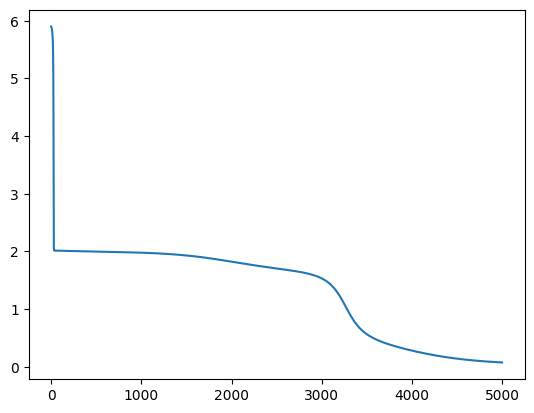

In [4]:
# Define the number of (visible) units in each layer
s = [2,8,8,1]

# Instantiate the network with data and topology, before running training
bp = Backpropogation(X,Y,s)
errors = bp.train(5000)
bp.test()

# Visualize Error over Epochs
plt.plot(errors)
plt.show()

In [5]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def standardize(x):
    col_means = np.mean(x,axis=0)
    col_std = np.std(x,axis=0)
    return (x - col_means) / col_std , col_means, col_std

## Cross Entropy Loss Function

### Motivation
In our derivation and explanation of the basic Backpropagation algorithm we made use of the mean squared error (MSE) loss function. Specifically we made use of the MSE to calculate the final error after training, but more importantly we also made use of the derivative of the MSE in determining our equations for propagating error from the output layer to the penultimate layer of the network.

To be more precise we calculated the derivative of the error E with respect to the input weights $\theta^{l-1}_{i}$ with the chain rule as follows:

\begin{equation}
\frac{\partial E}{\partial \theta^{l-1}_{i}} = \frac{\partial E}{\partial a}  \frac{\partial a}{\partial z}  \frac{\partial z}{\partial \theta^{l-1}_{i}}
\end{equation}

or

\begin{equation}
\frac{\partial E}{\partial \theta^{l-1}_{i}} = (a-y) \; (a (1-a)) \; a^{l-1}_{i}
\end{equation}

Unfortunately this equation is dependent on the partial derivative of $a$ with respect to $z$ which is given by $a\;(1-a)$. This term, the slope of the logistic activation function, introduces some problems for us and if we plot it we get an intuition of why this is the case.

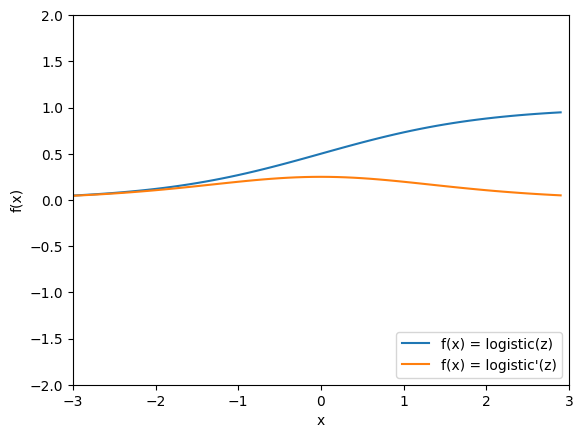

In [6]:
x1 = np.arange(-3,3,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z1 = np.matmul(np.array([0,1]),x)
a = (1 / (1 + np.exp(-z1)))

plt.plot(x1, a)
plt.plot(x1,np.multiply(a,(1 - a)))
plt.xlim([-3,3])
plt.ylim([-2,2])
plt.ylabel("f(x)")
plt.xlabel("x")
plt.legend(['f(x) = logistic(z)','f(x) = logistic\'(z)'], loc='lower right')
plt.show()

Unfortunately the logistic function has a derivative close to 0 both where the activation is close to 0 and close to 1. This is fine when the our target say is 0 and our activation is almost 0 but can equally happen when our target is 0 and our activation is hovering close to 1. The consequence of this is that our learning rate is slow when our activations are very wrong with respect to what they should be.

What we need to do is somehow remove $\frac{\partial E}{\partial \theta^{l-1}_{i}}$'s reliance on the partial derivative of the logistic activation function with respect to the logit. Unfortunately given our error and activation model there is nothing we can do to fix this.

### The Cross Entropy Loss Function

To overcome our problem and remove $\frac{\partial E}{\partial \theta^{l-1}_{i}}$'s dependence on the slope of the logistic function, we will introduce a new cost function -- well only new in our new context of neural networks. The new cost function will result in a new equation for $\frac{\partial E}{\partial a}$ which will in turn help to cancel out our reliance on the derivative of the logistic activation function.  

For this we will replace the MSE cost function with the Cross-Entropy Cost Function which is given below expressed in terms of a single activation value $a$ and target output $y$:

\begin{equation}
 cost_{CELF}(a,y) = - y \; log(a) - (1-y) log (1 - a)
\end{equation}

or

\begin{equation}
 cost_{CELF}(a,y) = - \big( y \; log(a) + (1-y) log (1 - a) \big)
\end{equation}

This is essentially the same error function that we used for logistic regression. This function works for binary targets where we know that predictions are bounded between 0 and 1. Cases where the target is close to the correct value incur a very small error whereas cases where the target is very wrong incur extremely large errors. Please see notes on logistic regression for more details.

Importantly for our purposes here we can calculate the partial derivative of this error function with respect to the activation values. We can start by noting that the partial derivative of the cost with respect to the activation $\frac{\partial E}{\partial a}$ is simply:

\begin{equation}
 \frac{\partial E}{\partial a} = \frac{y}{a} - \frac{1-y}{1-a}
\end{equation}

which we can rework over a common denominator:

\begin{equation}
 \frac{\partial E}{\partial a} = \frac{y(1-a) - (1-y)a}{a(1-a)}
\end{equation}

Multiplying out the top gives us:

\begin{equation}
 \frac{\partial E}{\partial a} = \frac{y - ya - a + ya} {a(1-a)}
\end{equation}

which is of course:

\begin{equation}
 \frac{\partial E}{\partial a} = \frac{y -a} {a(1-a)}
\end{equation}

We can substitute this into our equation for $\frac{\partial E}{\partial \theta^{l-1}_{i}}$ as follows:

\begin{equation}
\frac{\partial E}{\partial \theta^{l-1}_{i}} = \frac{y -a} {a(1-a)} \; (a (1-a)) \; a^{l-1}_{i}
\end{equation}

Allowing us to cancel out the $a(1-a)$ terms to give us:

\begin{equation}
\frac{\partial E}{\partial \theta^{l-1}_{i}} = (y -a) \; a^{l-1}_{i}
\end{equation}

This is a very simplified expression in comparison to our original MSE equivalent. We now have that the gradient of the error surface in the output layer with respect to activations in the penultimate layer is simply given by the equation $(y -a) \; a^{l-1}_{i}$. Note that our reliance on the derivative of the logistic function with respect to z is now gone and thus so is our problem where training can slow down when our predictions are very wrong.

For our hidden layers we can apply the same logic to the derivation of

\begin{equation}
 \frac{\partial E^{l}}{\partial a^{l-1}} = \delta^{l} \; \theta^{l-1}_{i}
\end{equation}

where $\delta = (y - a)$.

However the rest of our derivation of the recursive delta rule does not change resulting in a final delta update rule of:

\begin{equation}
  \delta^{l} = \sum_{j} ( \delta^{l+1} \; \theta^{l}_{i} ) \; g'(z^{l})
\end{equation}

which includes a $g'(z^{l})$ term, i.e., $a(1-a)$. It should be noted however that while we still have one instance of the gradient of a logit, this is still an improvement on our original MSE based equations.

We can demonstrate the use of the Cross Entropy Loss function along with its derivative by reworking our Backpropagation implementation to support Cross Entropy Loss function in addition to the Mean Square Error loss that was previously used.

In [7]:
# In this implementation we force all vectors to be true 2D arrays with 1 column rather than
# numpy 1D arrays. This makes it easier to use matirx operations.

def celf_(y,a):
    if y == 1:
        return -np.log(a)
    elif y == 0:
        return -np.log(1-a)

celf = np.vectorize(celf_)

class Backpropogation:

    def __init__(self,x,y,s,cost="mse"):
        # set class references to X, Y, S and the activation function
        self.X = x
        self.Y = y
        self.S = s
        self.cost = cost
        # Define empty arrays for activation
        self.a     =  [None] * len(self.S)
        # Define empty array for z values (i.e., inputs)
        self.z     =  [None] * len(self.S)
        # Define empty arrays for weights
        self.theta =  [None] * len(self.S)
        # Define empty array for error derivitives for indivual units
        self.delta =  [None] * len(self.S)
        # Define empty arrays for accumulated errors on weights
        self.Delta =  [None] * len(self.S)

        # Initialize the weights for all layers
        for idx, val in enumerate(self.S):
            if idx == (len(self.S)-1): # ouput layer has no weights
                break
            self.theta[idx] = np.random.rand( self.S[idx]+1,self.S[idx+1])

    # Calculate the cost
    def calcCost(self,a,y):
        if self.cost == "mse":
            return np.sum(np.multiply(0.5,(a-y)**2))
        elif self.cost == "celf":
            return np.sum(celf(y,a))
        else: print("Error - no cost function selected")

    # calculate the activation values given an input
    def calcActivation(self,z):
        return 1 / (1 + np.exp(-z))

    # calculate ∂a/∂z
    def calcGPrimeZ(self,a):
        return np.multiply(a,(1 - a))

    def forwardProp(self,x):
        # Forward propogate activation
        # For each layer from input to output
        for idx, val in enumerate(self.S):
            if idx == 0:
                # construct the activation values for the input layer from X and a bias value
                self.a[idx] = np.atleast_2d(np.hstack(([1.0],x))).T
            elif idx == (len(self.S)-1):
                # calculate z for the output layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate the activation values
                self.a[idx] = self.calcActivation(self.z[idx])
            else:
                # calculate z for a hidden layer
                self.z[idx] = np.atleast_2d(np.matmul(self.theta[idx-1].T,self.a[idx-1]))
                # calculate a for a hidden layer
                self.a[idx] = np.vstack(([1.0],self.calcActivation(self.z[idx])))
        # return the actual output values for the output layer
        return self.a[len(self.S)-1]

    def predict(self,X):
        results = []
        for datum in X:
            results.append(self.forwardProp(datum))
        return np.squeeze(results)

    def backwardProp(self,y):
        # For each layer from output to input
        for idx, val in reversed(list(enumerate(self.S))):
            if idx == (len(self.S)-1):
                if self.cost == "mse":
                    # calculate ∂a/∂z for the output layer
                    gprimez = self.calcGPrimeZ(self.a[idx])

                    # ∂E/∂zⱼ
                    self.delta[idx] = np.multiply(self.a[idx] - np.atleast_2d(y).T,gprimez)
                elif self.cost == "celf":
                    # ∂E/∂zⱼ
                    self.delta[idx] = -(np.atleast_2d(y).T - self.a[idx])
                else: print("Error - no cost function selected")
            elif idx == 0:
                # we need to update the weights in the 0th layer but we don't propogate error
                # derivitive back to the input units.
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T
            else:
                # calculate the error for all other layers

                # 1. calculate the derivitive of g(z)
                gprimez = self.calcGPrimeZ(self.a[idx])

                # 2. calculate the error associatd with each node in the current layer.
                self.delta[idx] = np.multiply(np.matmul(self.theta[idx],self.delta[idx+1]),gprimez)

                # get rid of the bias unit
                self.delta[idx] = self.delta[idx][1:,:]

                # 3. update the accumulated change
                self.Delta[idx] = self.Delta[idx] + np.matmul(self.delta[idx+1],self.a[idx].T).T

        return self.calcCost(self.a[len(self.S)-1],np.atleast_2d(y).T)

    def train(self,epochs):
        errors = []
        # For each training epoch
        for k in range(epochs):
            error = 0
            # Initialize Delta for this epoch
            for idx, val in enumerate(self.S):
                if idx < (len(self.S)-1): # ouput layer has no weights
                    self.Delta[idx] = np.zeros((self.S[idx]+1,self.S[idx+1]))
            # Iterate over all training examples
            for i, y in enumerate(self.Y):
                self.forwardProp(self.X[i])
                error += self.backwardProp(y)
            errors.append(error)
            # For each layer from output to input
            for idx, val in reversed(list(enumerate(self.S))):
                if idx < (len(self.S)-1):
                    # Update the weights
                    self.theta[idx] = self.theta[idx] - (1/len(self.Y)) * self.Delta[idx]
        return errors

    def test(self):
        for i, y in enumerate(self.Y):
            output = self.forwardProp(self.X[i])
            print(self.X[i])
            print(y)
            print(output)
            print("Error is " + str(self.calcCost(output,np.atleast_2d(y).T)))
            print("---")

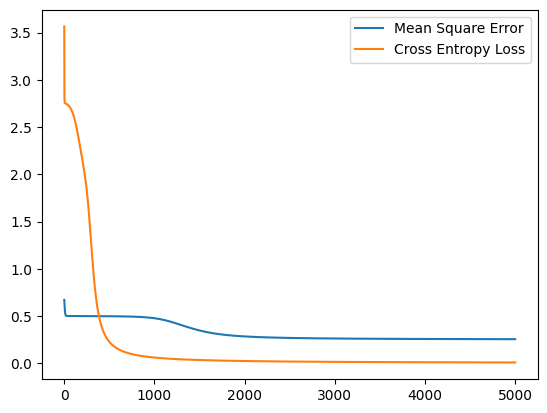

In [8]:
# Define the training data
Y = np.array([  0,1,1,0])
X1 = np.array([ 0,0,1,1])
X2 = np.array([ 0,1,0,1])
X = np.vstack((X1,X2)).T

# Define the number of (visible) units in each layer
s = [2,2,1]

# Instantiate the network with data and topology, before running training and printing results
bp = Backpropogation(X,Y,s,cost="mse")
errors = bp.train(5000)

# Visualize Error over Epochs
plt.plot(errors)

# Instantiate the network with data and topology, before running training and printing results
bp = Backpropogation(X,Y,s,cost="celf")
errors = bp.train(5000)

# Visualize Error over Epochs
plt.plot(errors)
plt.legend(['Mean Square Error','Cross Entropy Loss'], loc='upper right')
plt.show()

It should be noted that in the above that the final error with CELF can be higher than that measured with MSE. This does not mean that CELF is doing worse that MSE. CELF and MSE have different values for the same target and activation values. This is easily shown by calculating the MSE and CELF for the same target and activation vectors.

In [9]:
Y = np.array([0,0,1,1])
A = np.array([0.1,0.9,0.1,0.9])

s = np.sum(celf(Y,A))
print("CELF error for the target and activation vectors was " + str(s))

s = np.sum(np.multiply(0.5,(A-Y)**2))
print("MSE error for the same vectors was " + str(s))

CELF error for the target and activation vectors was 4.815891217303744
MSE error for the same vectors was 0.8200000000000001


What is important to note in the example above is that the error with CELF reduced quite quickly in terms of the number of epochs which the training based on MSE took many more epochs.

## Exercise -- Exploring Network Configurations with Keras

Everything above was implemented by hand so that you can see exactly what backpropagation is doing. In practice we rarely write the backward pass ourselves. Libraries such as **Keras** construct the network, compute the gradients for us, and apply the weight updates. The underlying mathematics is exactly the same as in the notes above: a forward pass, a loss (MSE or cross entropy), a backward pass of $\delta$ values, and a gradient descent update of the weights.

In this exercise you will use Keras to build a number of feedforward networks and compare how **quickly** and how **accurately** each of them trains. To keep us aligned with the notes, we restrict ourselves to:

- fully connected feedforward (`Dense`) layers only
- **logistic** (`sigmoid`) or **linear** activation functions in the hidden layers
- a single logistic output unit, trained with either **MSE** or **cross entropy** loss
- plain (stochastic) gradient descent, `SGD`, as the update rule

The things you will vary are the **depth** of the network (number of hidden layers), its **width** (units per layer), the **hidden activation**, and the **loss function**.

### The Problem: Two Interleaved Spirals

Our earlier ring example could be solved by a small network in a few epochs. To make the choice of architecture actually matter we use a harder non-linear problem: two interleaved spirals, one per class. No straight line (or single logistic unit) can separate them.

We generate 1000 points, split them into 800 training and 200 validation examples, and standardise the inputs using the training statistics (just as we did with `standardize` above).

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow start-up chatter

import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
import keras

def make_spirals(n_per_class=500, turns=1.0, noise=0.045, seed=0):
    # Two interleaved spirals: class 0 and class 1 are 180 degrees apart
    rng = np.random.default_rng(seed)
    t = np.sqrt(rng.uniform(0, 1, n_per_class)) * turns * 2 * np.pi
    r = t / (2 * np.pi * turns) + 0.1
    spiral = np.c_[r * np.cos(t), r * np.sin(t)]
    X = np.vstack([spiral, -spiral]) + rng.normal(0, noise, (2 * n_per_class, 2))
    y = np.r_[np.zeros(n_per_class), np.ones(n_per_class)]
    return X, y

X, y = make_spirals()

# Shuffle, then split into training and validation sets
idx = np.random.default_rng(1).permutation(len(y))
X, y = X[idx], y[idx]
X_train, y_train = X[:800], y[:800]
X_val,   y_val   = X[800:], y[800:]

# Standardise using the training set statistics only
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu) / sigma
X_val   = (X_val - mu) / sigma

plt.figure(figsize=(5, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=10)
plt.title("Training data: two interleaved spirals")
plt.axis("equal")
plt.show()

### A Helper for Building and Training a Network

The function below builds, trains and reports on a network described by a handful of settings. The most important argument is `hidden_layers`, a list giving the number of units in each hidden layer:

| `hidden_layers` | Network |
| --- | --- |
| `[]` | no hidden layer -- this is just logistic regression |
| `[8]` | one hidden layer of 8 units |
| `[16, 16]` | two hidden layers of 16 units each |
| `[16, 16, 16, 16]` | four hidden layers of 16 units each |

Note that this plays the same role as the list `s` in our hand-written implementation, except that Keras works out the input size from the data and we add the single output unit automatically.

For each run we record three things:

- **Final validation accuracy** -- how well did the trained network do on data it did not train on?
- **Epochs to 90%** -- the first epoch at which validation accuracy reached 90%. This is our measure of *speed of learning*; `None` means it never got there.
- **Wall-clock time** -- how long training took on your machine. With a dataset this small most of the time is Keras overhead per batch, so expect wall-clock times to be similar across networks; epochs to 90% is the more informative measure of learning speed here.

We fix the random seed so that re-running a configuration gives the same result. Once you have finished the main tasks, try changing the `seed` to see how much results depend on the random initial weights.

In [ ]:
def run_experiment(hidden_layers, activation="sigmoid", loss="binary_crossentropy",
                   learning_rate=0.5, epochs=200, batch_size=32, seed=42, verbose=True):
    keras.utils.set_random_seed(seed)

    # Build the network: input -> hidden layers -> one logistic output unit
    model = keras.Sequential([keras.Input(shape=(2,))])
    for units in hidden_layers:
        model.add(keras.layers.Dense(units, activation=activation))
    model.add(keras.layers.Dense(1, activation="sigmoid"))

    # loss is either "binary_crossentropy" (i.e. CELF) or "mse"
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=learning_rate),
                  loss=loss, metrics=["accuracy"])

    start = perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size, verbose=0)
    elapsed = perf_counter() - start

    val_acc = np.array(history.history["val_accuracy"])
    reached = np.where(val_acc >= 0.9)[0]
    result = {
        "label": f"{hidden_layers} {activation} {loss}",
        "model": model,
        "history": history.history,
        "params": model.count_params(),
        "val_acc": val_acc[-1],
        "epochs_to_90": int(reached[0]) + 1 if len(reached) else None,
        "seconds": elapsed,
    }
    if verbose:
        print(f"{result['label']:<45} params={result['params']:<5} "
              f"val_acc={result['val_acc']:.3f}  epochs_to_90%={result['epochs_to_90']}  "
              f"time={elapsed:.1f}s")
    return result

def plot_histories(results, metric="loss"):
    # Compare training curves (loss or accuracy) for several runs
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for r in results:
        axes[0].plot(r["history"][metric], label=r["label"])
        axes[1].plot(r["history"]["val_accuracy"], label=r["label"])
    axes[0].set_title(f"Training {metric}"); axes[0].set_xlabel("epoch")
    axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch")
    axes[1].axhline(0.9, color="grey", linestyle=":")
    axes[1].legend(fontsize=8, loc="lower right")
    plt.show()

def plot_decision_boundary(result):
    # Colour the input space by the network's prediction
    xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    probs = result["model"].predict(grid, verbose=0).reshape(xx.shape)
    plt.figure(figsize=(5, 5))
    plt.contourf(xx, yy, probs, levels=20, cmap="coolwarm", alpha=0.6)
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=8, edgecolors="k", linewidths=0.2)
    plt.title(result["label"])
    plt.axis("equal")
    plt.show()

### A First Run

Let's start with a network with a single hidden layer of 8 logistic units, trained with cross entropy loss. Look at the loss curve, the validation accuracy, and the decision boundary the network has learned.

In [ ]:
baseline = run_experiment([8])
plot_histories([baseline])
plot_decision_boundary(baseline)

### Comparing Configurations

Now we train a set of networks that differ in depth, activation and loss. Each takes some seconds to train, so this cell will take a few minutes to run.

In [ ]:
configs = [
    dict(hidden_layers=[]),                           # no hidden layer: logistic regression
    dict(hidden_layers=[8]),                          # shallow and narrow
    dict(hidden_layers=[32]),                         # shallow and wide
    dict(hidden_layers=[16, 16]),                     # two hidden layers
    dict(hidden_layers=[16, 16, 16, 16, 16, 16]),     # deep
    dict(hidden_layers=[16, 16], activation="linear"),# two hidden layers, linear activation
    dict(hidden_layers=[16, 16], loss="mse"),         # two hidden layers, MSE loss
]

results = [run_experiment(**c) for c in configs]

In [ ]:
plot_histories(results)

for r in results:
    plot_decision_boundary(r)

### Tasks

Work through the following using `run_experiment`. For each, note the validation accuracy, the epochs to 90%, and look at the loss curve and decision boundary. Write a short (2-3 sentence) answer to each question, relating what you see back to the equations in the notes above.

1. **No hidden layer.** What accuracy does `[]` reach, and what shape is its decision boundary? Why can it never solve this problem?

2. **Linear hidden units.** Compare `[16, 16]` with `activation="linear"` against the network with no hidden layer. Why do the two linear hidden layers add nothing? (Hint: what is a linear function of a linear function?) Try adding more linear layers to confirm.

3. **Width vs. depth.** Compare `[32]` with `[16, 16]` and `[8, 8, 8, 8]`. Which learns fastest? Which has the most parameters? Is more parameters always better?

4. **Going too deep.** The six-layer logistic network does not learn at all within 200 epochs. Recall the derivative of the logistic function, $a(1-a)$, which is at most 0.25, and that the recursive $\delta$ rule multiplies by it once per layer. Explain what happens to $\delta$ in the early layers of a deep logistic network. Try 3, 4 and 5 hidden layers: at what depth does training break down? Does giving it more epochs (e.g. `epochs=1000`) or a larger `learning_rate` help?

5. **Loss function.** Compare the MSE and cross entropy runs for `[16, 16]`. Which reaches 90% first? Relate this to the discussion of the $a(1-a)$ term in the Cross Entropy section above. Note that you should compare *accuracy* rather than the loss values themselves, since the two losses are on different scales.

6. **Learning rate.** Pick the configuration you think is best and try `learning_rate` values of 0.05, 0.5, 2 and 10. What happens to speed and stability of training?

7. **Your best network.** Find the smallest network (fewest parameters) that reaches at least 95% validation accuracy within 200 epochs. Report its configuration and results. Then change `seed` a few times: is your result robust to the random starting weights?

In [ ]:
# Your experiments here. For example:
r = run_experiment([8, 8, 8, 8])
plot_histories([baseline, r])
plot_decision_boundary(r)

**Optional challenge:** increase the difficulty of the problem by regenerating the data with `make_spirals(turns=1.5)` (re-run the data cell, then your experiments). How do your conclusions about depth, width and learning rate change as the problem gets harder?